Hyperspectral Image Classification

In [ ]:
!pip install spectral
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from spectral import imshow, get_rgb
import scipy.io as sio
import os
import glob
import random
from sklearn.model_selection import train_test_split

First, we load in the data.

Data Shape: (512, 217, 204)


Text(0.5, 1.0, 'Ground Truth')

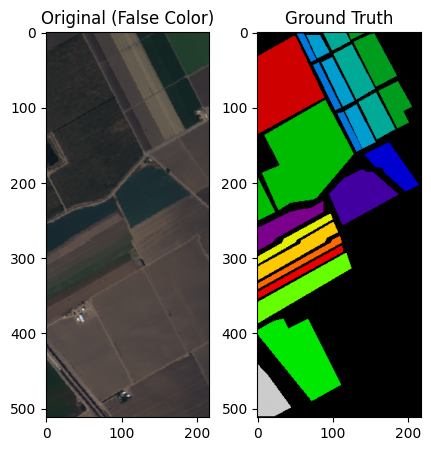

In [ ]:
# data available here: https://www.ehu.eus/ccwintco/index.php/Hyperspectral_Remote_Sensing_Scenes#Salinas

data = sio.loadmat('Salinas_corrected.mat')['salinas_corrected']
gt = sio.loadmat('Salinas_gt.mat')['salinas_gt']

print(f"Data Shape: {data.shape}") # (512, 217, 204)
fig, ax = plt.subplots(1, 2, figsize=(5, 5))
# 1. False Color Composite (using specific bands for RGB)
ax[0].imshow(get_rgb(data, [29, 19, 9]))
ax[0].set_title("Original (False Color)")
# 2. Ground Truth Labels
ax[1].imshow(gt, cmap='nipy_spectral')
ax[1].set_title("Ground Truth")

Next, we pick out a sample pixel from each class and examine it's reflectance spectrum

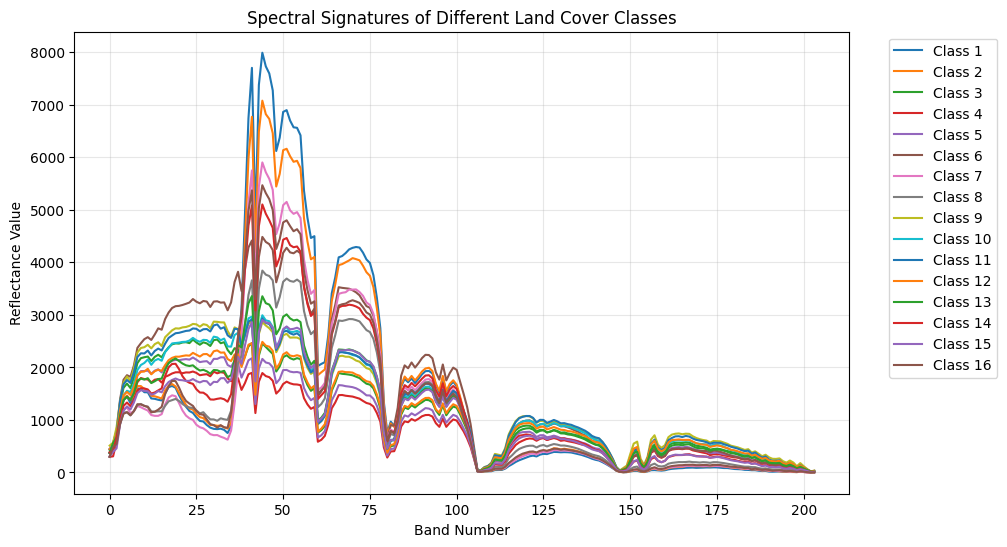

In [ ]:
plt.figure(figsize=(10, 6))
classes = np.unique(gt)
# Skip class 0 (background)
for class_id in classes[1:]:
  # Find coordinates of all pixels belonging to this class
  idx = np.argwhere(gt == class_id)
  # Pick the first pixel found for this class
  pixel_coords = idx[0]
  spectrum = data[pixel_coords[0], pixel_coords[1], :]

  plt.plot(spectrum, label=f'Class {class_id}')

plt.title("Spectral Signatures of Different Land Cover Classes")
plt.xlabel("Band Number")
plt.ylabel("Reflectance Value")
plt.legend(loc='upper right', bbox_to_anchor=(1.2, 1))
plt.grid(True, alpha=0.3)
plt.show()

This raw reflectance spectrum is not always the most useful format to classify on, so we can normalize by the maximum relfectance signal instead. We can observe that the different classes are now more easily distinguishable by eye!

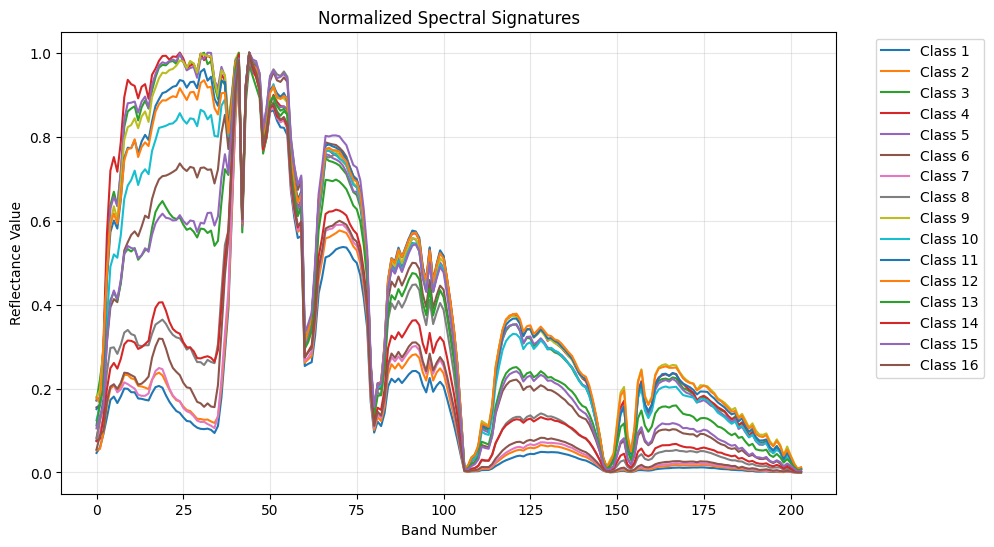

In [ ]:
plt.figure(figsize=(10, 6))
classes = np.unique(gt)
# Skip class 0 (background)
for class_id in classes[1:]:
  # Find coordinates of all pixels belonging to this class
  idx = np.argwhere(gt == class_id)
  # Pick the first pixel found for this class
  pixel_coords = idx[0]
  spectrum = data[pixel_coords[0], pixel_coords[1], :]
  normalized_spectrum = spectrum / np.max(spectrum)

  plt.plot(normalized_spectrum, label=f'Class {class_id}')

plt.title("Normalized Spectral Signatures")
plt.xlabel("Band Number")
plt.ylabel("Reflectance Value")
plt.legend(loc='upper right', bbox_to_anchor=(1.2, 1))
plt.grid(True, alpha=0.3)
plt.show()

Next, we perform principal component analysis to reduce the size of the data. Basically, the 204 spectral dimensions are way overkill to accurately classify the scene. Therefore, we can change basis to the principal axes of variability and discard the irrelevant dimensions. As you can see, 99.85% of the variability is captured in 5 dimensions! This can compresses the data a lot.

In [ ]:
# Flatten the 3D cube to 2D (pixels x bands) for PCA
pixels = data.reshape(-1, data.shape[2])
pixel_classes = gt.flatten()

# Reduce to 30 components
pca = PCA(n_components=30)
data_pca = pca.fit_transform(pixels)

# Reshape back to spatial dimensions
data_pca_reshaped = data_pca.reshape(data.shape[0], data.shape[1], 30)
print(f"shape (height x width x spectra): {data_pca_reshaped.shape}") # reduced to a pixel depth of 30

explained_variance = pca.explained_variance_ratio_
print("Explained Variance for the first 5 Principal Components:")
for i in range(5):
  percentage = explained_variance[i] * 100
  print(f"PC{i+1}: {explained_variance[i]:.4f} ({percentage:.2f}%)")
print(f"Cumulative: {np.sum(explained_variance[:5]) * 100:.2f}%")

shape (height x width x spectra): (512, 217, 30)
Explained Variance for the first 5 Principal Components:
PC1: 0.7447 (74.47%)
PC2: 0.2353 (23.53%)
PC3: 0.0113 (1.13%)
PC4: 0.0054 (0.54%)
PC5: 0.0017 (0.17%)
Cumulative: 99.85%


We can plot individual classes on the first and second principal component axes. These will clump up in different areas, allowing us to distinguish the classes by eye.

/tmp/ipython-input-678692739.py:12: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  scatter = plt.scatter(X_subset[:, 0], X_subset[:, 1],


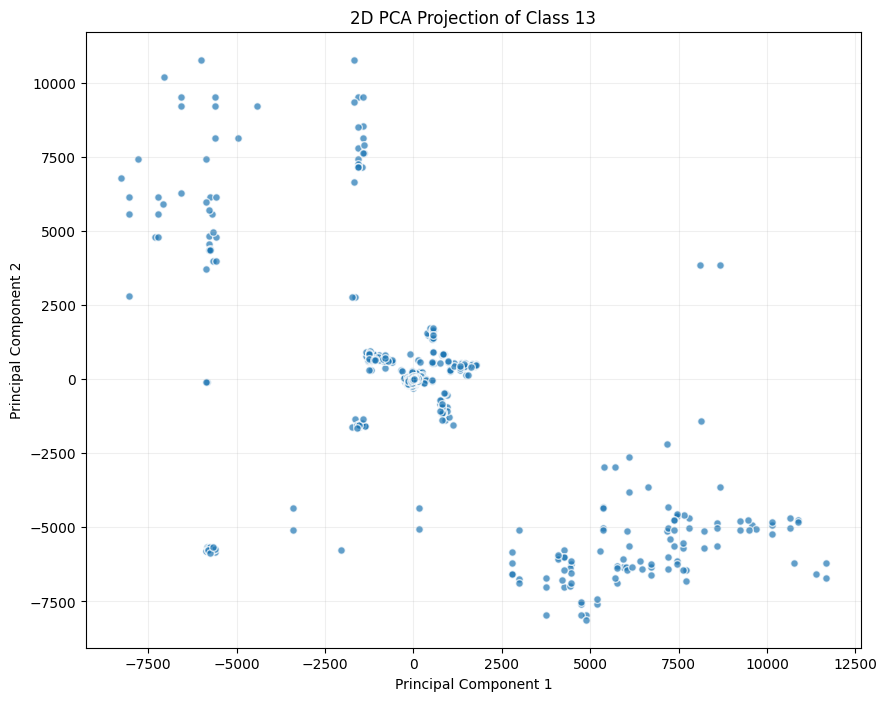

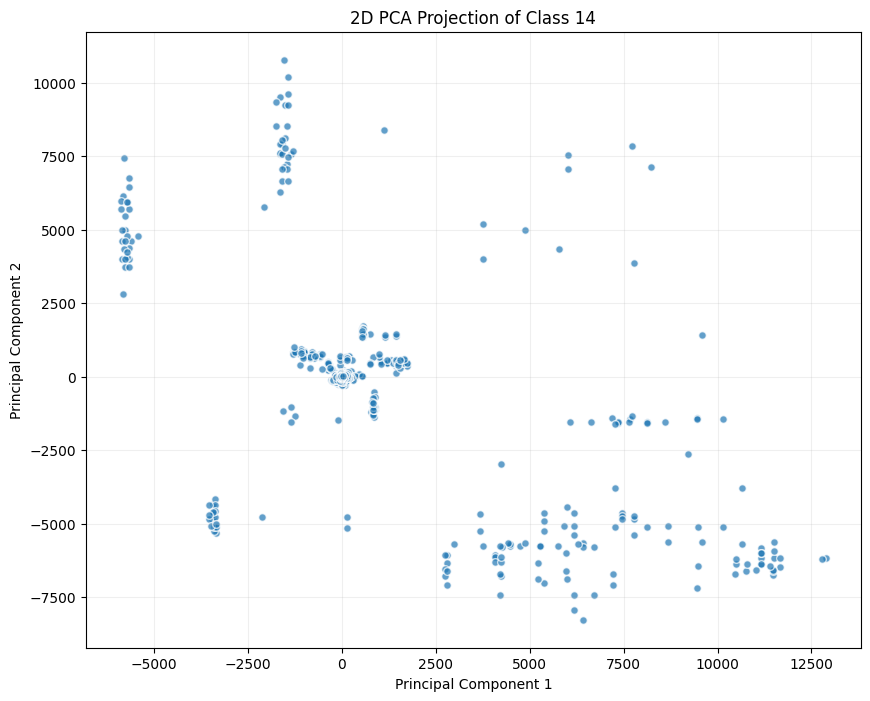

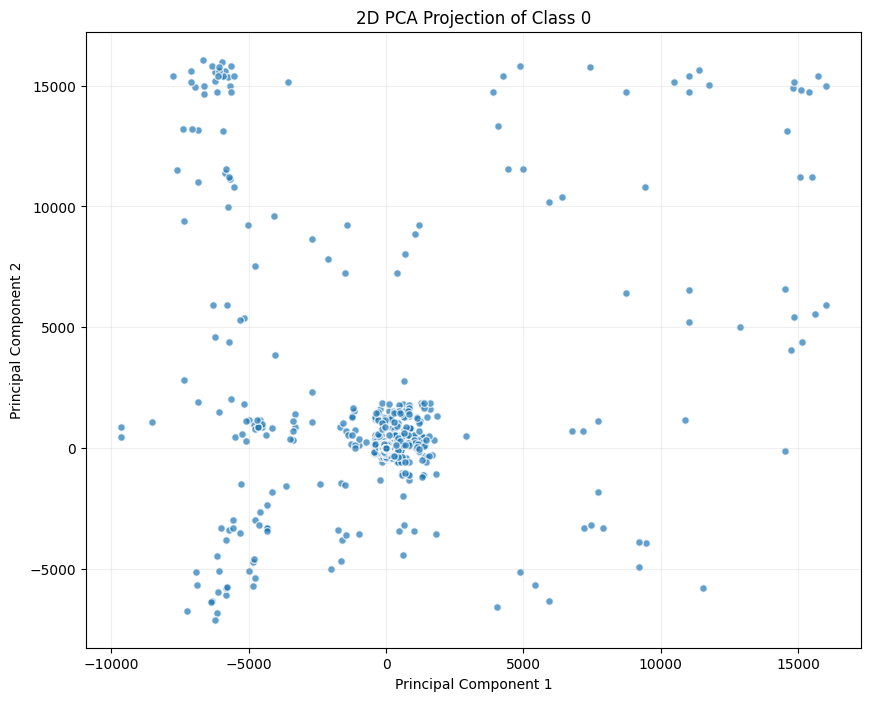

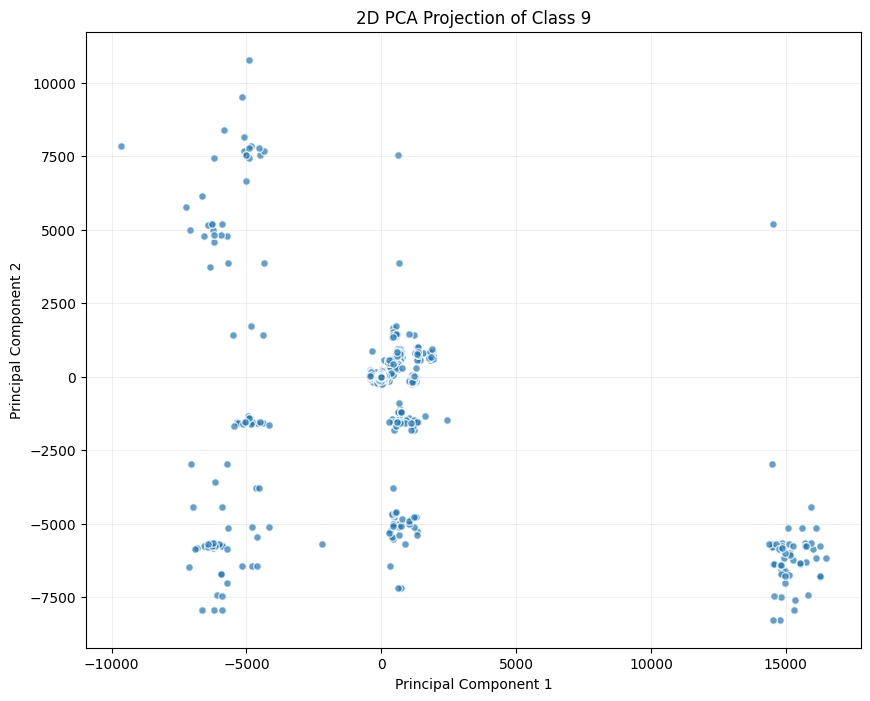

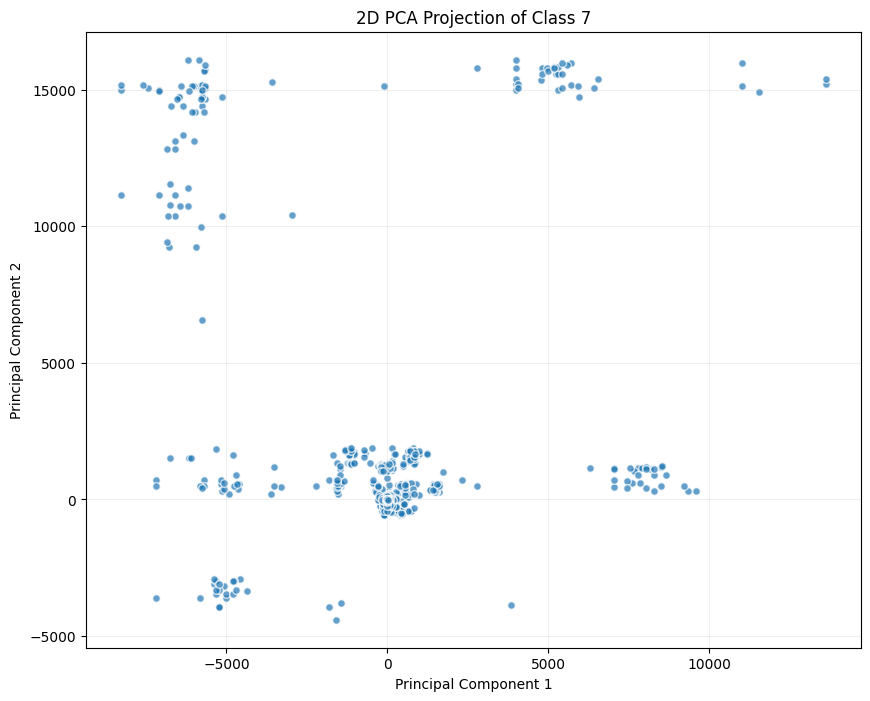

In [ ]:
for class_id in random.sample(classes.tolist(), k=5):
  # Find coordinates of all pixels belonging to this class
  idx = np.argwhere(gt == class_id)
  this_class_spectra = data_pca[idx]

  plt.figure(figsize=(10, 8))
  # We use the X_labeled and y_labeled created in the previous step
  # Only plot a subset (e.g., 2000 pixels) to keep the plot clean
  subset_indices = np.random.choice(len(this_class_spectra), 100, replace=False)
  X_subset = this_class_spectra[subset_indices]

  scatter = plt.scatter(X_subset[:, 0], X_subset[:, 1],
              cmap='nipy_spectral', edgecolor='w', s=30, alpha=0.7)

  plt.title(f"2D PCA Projection of Class {class_id}")
  plt.xlabel("Principal Component 1")
  plt.ylabel("Principal Component 2")
  plt.grid(True, alpha=0.2)
  plt.show()

Here's a sample of all classes on the same plot. Some classes are easy to distinguish (teal and purple). Other classes are heavily mixed with others (green and red). Investigating and interpreting these plots is one of the main methods of analysis for this team.

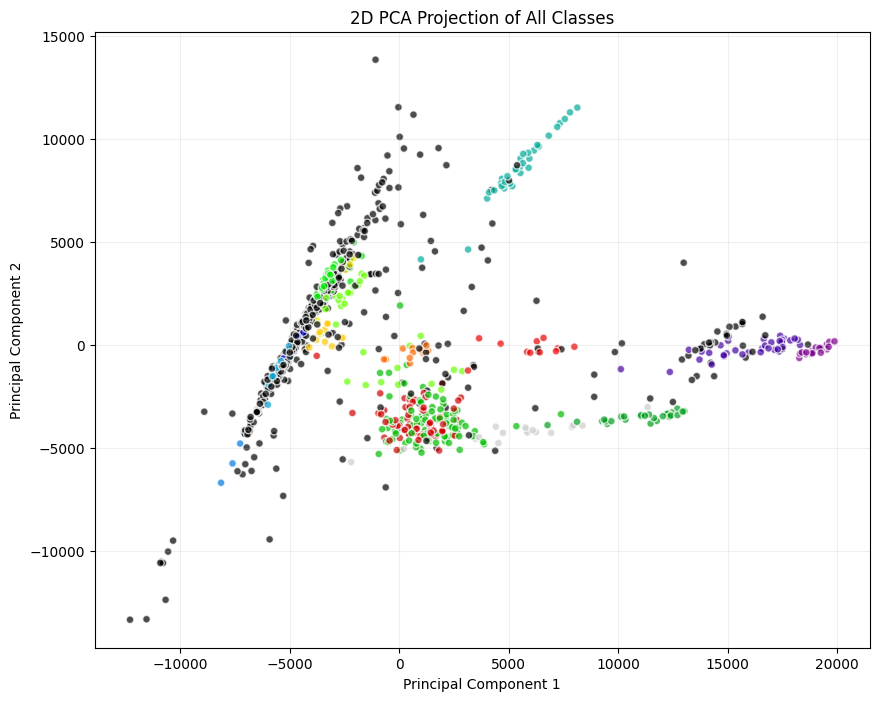

In [ ]:
plt.figure(figsize=(10, 8))
# We use the X_labeled and y_labeled created in the previous step
# Only plot a subset (e.g., 2000 pixels) to keep the plot clean
subset_indices = np.random.choice(len(data_pca), 1000, replace=False)
X_subset = data_pca[subset_indices]
Y_subset = pixel_classes[subset_indices]

scatter = plt.scatter(X_subset[:, 0], X_subset[:, 1], c=Y_subset,
            cmap='nipy_spectral', edgecolor='w', s=30, alpha=0.7)

plt.title(f"2D PCA Projection of All Classes")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.2)
plt.show()

We can also plot on the "further down" axes. The theory behind PCA indicates that these represent finer detail in the distribution of our data. Qualitatively, data that overlap for PCA components

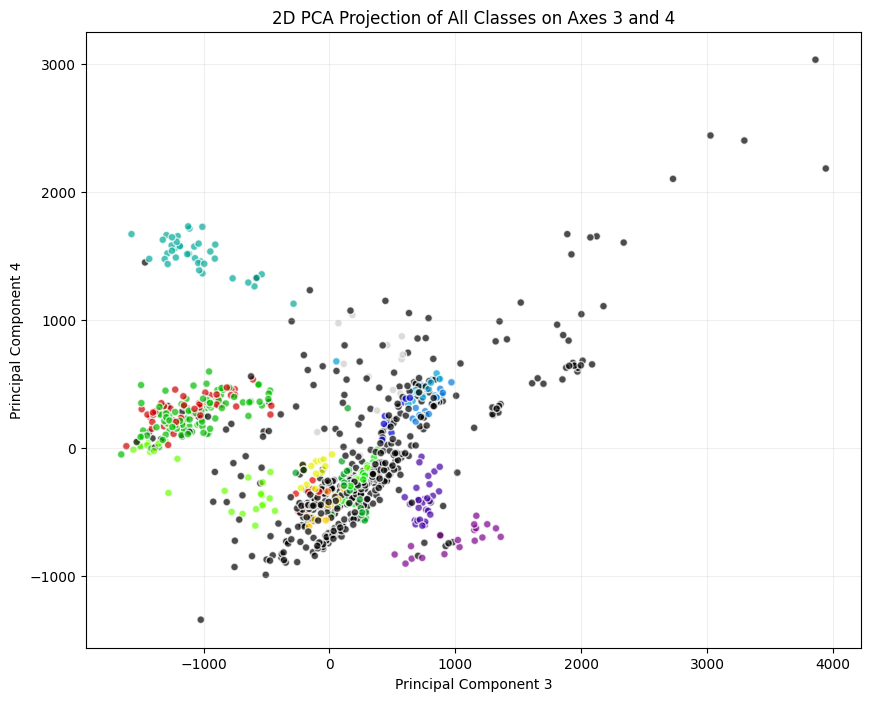

In [ ]:
plt.figure(figsize=(10, 8))
# We use the X_labeled and y_labeled created in the previous step
# Only plot a subset (e.g., 2000 pixels) to keep the plot clean
subset_indices = np.random.choice(len(data_pca), 1000, replace=False)
X_subset = data_pca[subset_indices]
Y_subset = pixel_classes[subset_indices]

scatter = plt.scatter(X_subset[:, 2], X_subset[:, 3], c=Y_subset,
            cmap='nipy_spectral', edgecolor='w', s=30, alpha=0.7)

plt.title(f"2D PCA Projection of All Classes on Axes 3 and 4")
plt.xlabel("Principal Component 3")
plt.ylabel("Principal Component 4")
plt.grid(True, alpha=0.2)
plt.show()

Here, we train a Random Forest classifier on our pca-compressed data.

In [ ]:
# Prepare training data (X = PCA features, y = labels)
y = gt.ravel()
X = data_pca

# Filter out unlabeled pixels (class 0)
X_labeled = X[y > 0]
y_labeled = y[y > 0]

# Train the model
clf = RandomForestClassifier(n_estimators=100, n_jobs=-1)
clf.fit(X_labeled, y_labeled)

# Predict the entire image
y_pred = clf.predict(X)
classification_map = y_pred.reshape(gt.shape)

Finally, we can plot the predicted classes from the data trained on a sample of the ground truth data. The performance is not too bad for this very small amount of data!

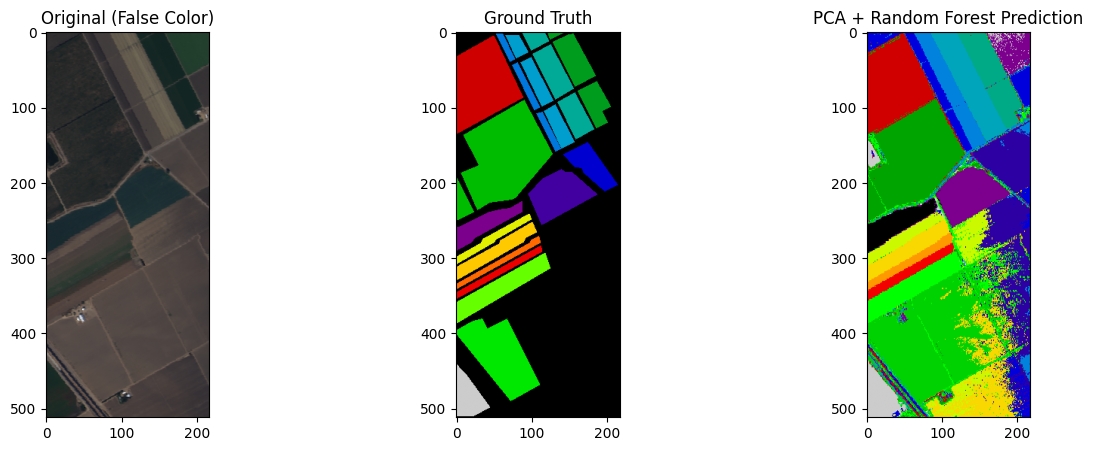

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

# 1. False Color Composite (using specific bands for RGB)
ax[0].imshow(get_rgb(data, [29, 19, 9]))
ax[0].set_title("Original (False Color)")

# 2. Ground Truth
ax[1].imshow(gt, cmap='nipy_spectral')
ax[1].set_title("Ground Truth")

# 3. Predicted Map
ax[2].imshow(classification_map, cmap='nipy_spectral')
ax[2].set_title("PCA + Random Forest Prediction")

plt.show()